In [2]:
import gymnasium as gym

# Initialise the environment
env = gym.make("LunarLander-v3", render_mode="human")

# Reset the environment to generate the first observation
observation, info = env.reset(seed=42)
for _ in range(1000):
    # this is where you would insert your policy
    action = env.action_space.sample()

    # step (transition) through the environment with the action
    # receiving the next observation, reward and if the episode has terminated or truncated
    observation, reward, terminated, truncated, info = env.step(action)

    # If the episode has ended then we can reset to start a new episode
    if terminated or truncated:
        observation, info = env.reset()

env.close()

## Maze Debugging

In [7]:
from pyamaze import maze
import pandas as pd
import tkinter as tk
import matplotlib.pyplot as plt

In [ ]:

tk.Tk.state = lambda self, s=None: self.wm_state('normal' if s == 'zoomed' else s)
def generate_df_maze(rows=20, cols=20, lp=80):
    # Create a Pyamaze maze
    m = maze(rows, cols)
    m.CreateMaze(loopPercent=lp)  # No loops to match a grid-like maze

    # List to store cell data
    maze_data = []
    for y in range(1, rows + 1):
        for x in range(1, cols + 1):
            cell = (x, y)
            cell_walls = m.maze_map[cell]  # Get wall info for each cell

            E = 1 if cell_walls['E'] else 0
            W = 1 if cell_walls['W'] else 0
            N = 1 if cell_walls['N'] else 0
            S = 1 if cell_walls['S'] else 0

            maze_data.append([f"({x},{y})", E, W, N, S])

    df = pd.DataFrame(maze_data, columns=["  cell  ", "E", "W", "N", "S"])
    if '  cell  ' in df.columns:
        df[['row', 'col']] = (
            df['  cell  '].astype(str)
            .str.replace(r'[()]', '', regex=True)
            .str.split(',', expand=True)
            .astype(int)
        )
    return df, m

In [3]:
# df_maze, m = generate_df_maze(
#             5,
#             5,
#             40
#         )
df_maze = pd.read_csv("data/rl_maze.csv")

In [14]:
m.run()

In [37]:
df_maze.iloc[44]

  cell      (5,5)
E               1
W               0
N               1
S               1
row             5
col             5
Name: 44, dtype: object

In [4]:
import networkx as nx
def _build_graph(df_maze):
        G = nx.Graph()
        for _, row in df_maze.iterrows():
            r, c = int(row['row']), int(row['col'])
            G.add_node((r, c))
            if row['E'] == 1:
                G.add_edge((r, c), (r, c+1))
            if row['W'] == 1:
                G.add_edge((r, c), (r, c - 1))
            if row['N'] == 1:
                G.add_edge((r, c), (r - 1, c))
            if row['S'] == 1:
                G.add_edge((r, c), (r + 1,c))
        return G

In [5]:
G = _build_graph(df_maze)

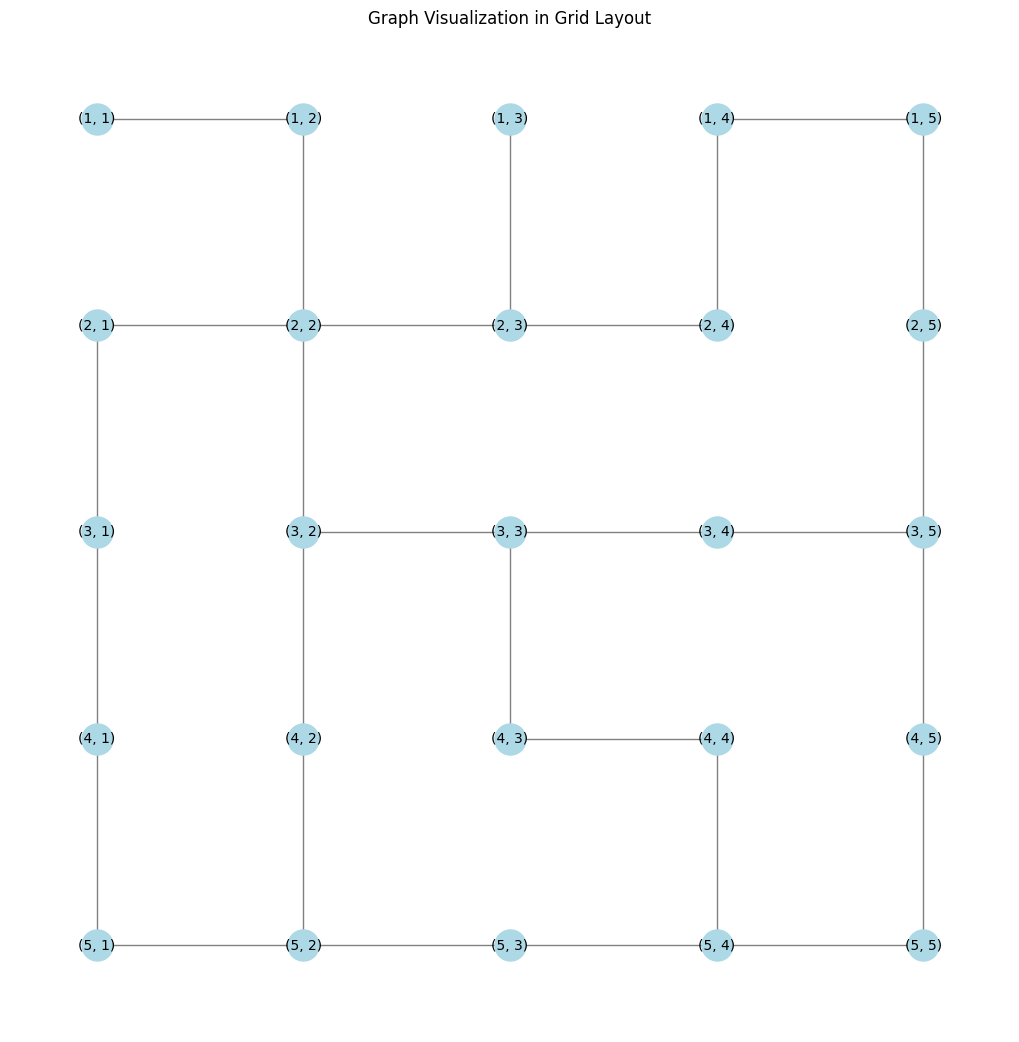

In [8]:
# Arrange nodes in a grid layout
pos = {(row['col'], row['row']): (row['row'], -row['col']) for _, row in df_maze.iterrows()}

# Draw the graph
plt.figure(figsize=(10, 10))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color='gray')
plt.title("Graph Visualization in Grid Layout")
plt.show()

In [34]:
# Print the edges of the center node
max_row = df_maze['row'].max()
max_col = df_maze['col'].max()
center_row = max_row // 2
center_col = max_col // 2
center_node = (center_col, center_row)
edges = G.edges(center_node)
print(f"Edges of the center node {center_node}: {list(edges)}")

Edges of the center node (np.int64(5), np.int64(5)): [((np.int64(5), np.int64(5)), (4, 5)), ((np.int64(5), np.int64(5)), (5, 6)), ((np.int64(5), np.int64(5)), (6, 5))]


In [18]:
df_maze.to_csv("data/rl_maze.csv", index=False)

## Plotting the Training Log

## SARSA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_results = pd.read_csv("runs/c75c5609/train_log.txt")

df_results.head()

,Episode,Total Reward,Epsilon
0,1,-112.8,0.2000
1,2,-29.1,0.1980
2,3,-116.7,0.1960
3,4,-3.6,0.1941
4,5,0.0,0.1921


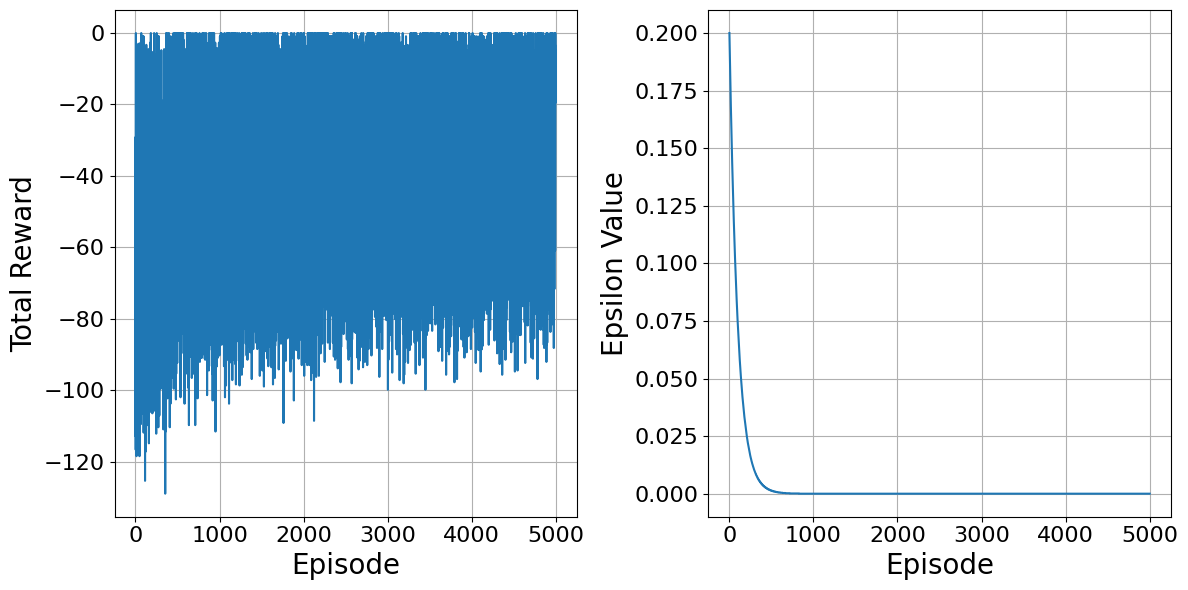

In [2]:
plt.figure(figsize=(12, 6))

fontsize_title = 20
fontsize_label = 20
fontsize_ticks = 16

# Plot 1: Total Reward over episodes
ax1 = plt.subplot(1, 2, 1)
ax1.plot(df_results['Episode'], df_results[' Total Reward'])
# ax1.set_title('Total Reward per Episode', fontsize=fontsize_title)
ax1.set_xlabel('Episode', fontsize=fontsize_label)
ax1.set_ylabel('Total Reward', fontsize=fontsize_label)
ax1.tick_params(axis='both', which='major', labelsize=fontsize_ticks)
ax1.grid(True)

# Plot 2: Epsilon over episodes
ax2 = plt.subplot(1, 2, 2)
ax2.plot(df_results['Episode'], df_results[' Epsilon'])
# ax2.set_title('Epsilon Decay over Episodes', fontsize=fontsize_title)
ax2.set_xlabel('Episode', fontsize=fontsize_label)
ax2.set_ylabel('Epsilon Value', fontsize=fontsize_label)
ax2.tick_params(axis='both', which='major', labelsize=fontsize_ticks)
ax2.grid(True)

plt.tight_layout()
plt.show()

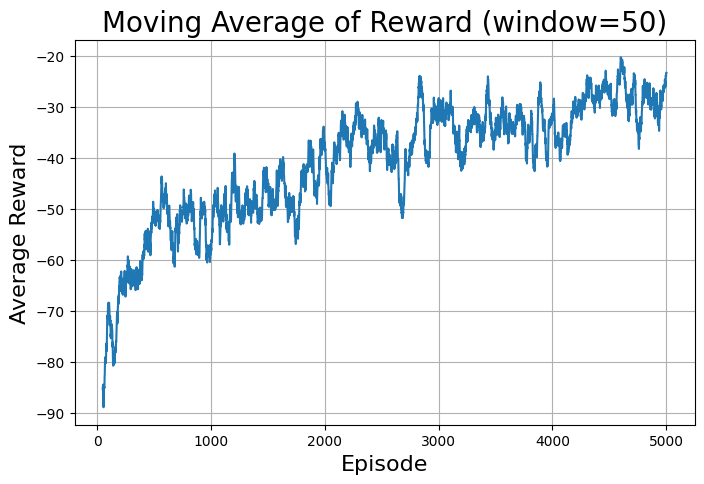

In [5]:
window_size = 50  # Adjust this for smoother or more responsive averaging
moving_avg = df_results[' Total Reward'].rolling(window=window_size).mean()

plt.figure(figsize=(8, 5))
plt.plot(df_results['Episode'][window_size-1:], moving_avg[window_size-1:])
plt.title(f'Moving Average of Reward (window={window_size})', fontsize=fontsize_title)
plt.xlabel('Episode', fontsize=fontsize_label)
plt.ylabel('Average Reward', fontsize=fontsize_label)
plt.grid(True)
plt.show()

## DQN

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fontsize_title = 22
fontsize_label = 26
fontsize_ticks = 22

In [17]:
ep_ret_df = pd.read_csv("runs/a3b197ac/training_returns.csv")
ep_q_df = pd.read_csv("runs/a3b197ac/training_q.csv")
ep_loss_df = pd.read_csv("runs/a3b197ac/training_loss.csv")

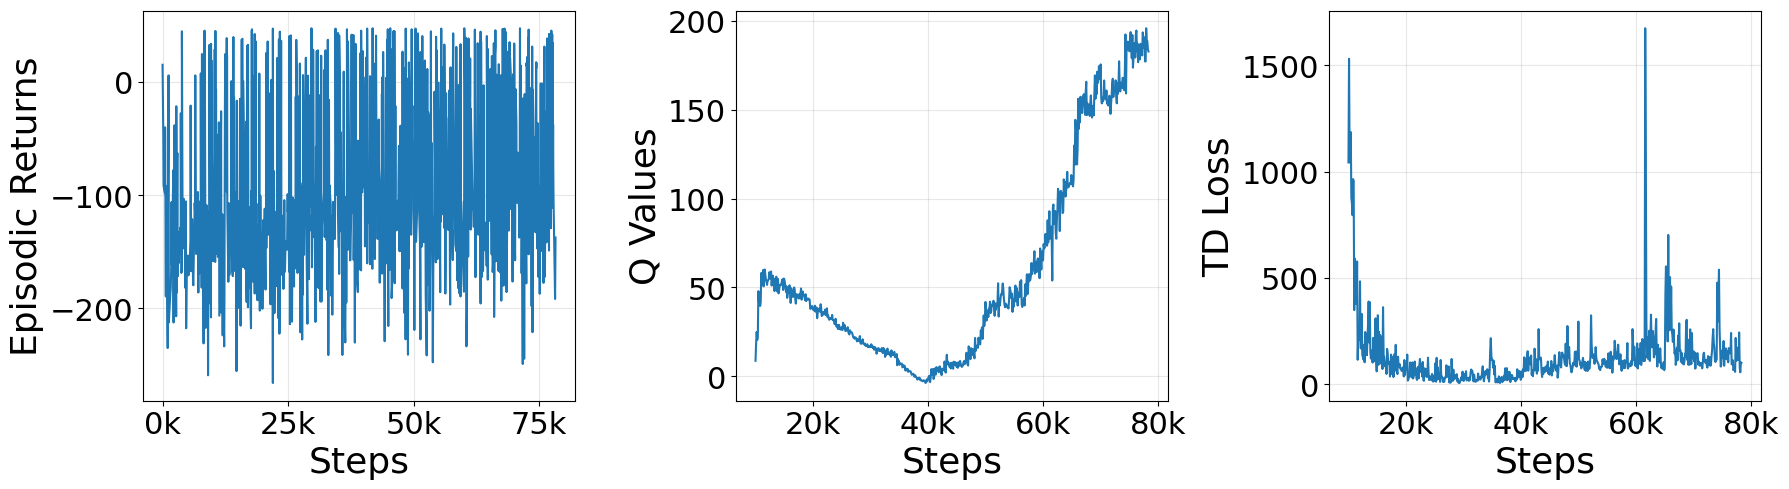

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)

def k_formatter(x, pos):
    """The function to format the tick labels."""
    return f'{x*1e-3:.0f}k'

# Plot Episode Returns
ax = axes[0]
ax.plot(ep_ret_df['Step'], ep_ret_df['Value'])
ax.xaxis.set_major_formatter(ticker.FuncFormatter(k_formatter))
axes[0].set_xlabel('Steps', fontsize=fontsize_label)
axes[0].set_ylabel('Episodic Returns', fontsize=fontsize_label)
axes[0].tick_params(axis='x', labelsize=fontsize_ticks)
axes[0].tick_params(axis='y', labelsize=fontsize_ticks)
ax.grid(True,alpha=0.3)

# Plot Q Values
ax = axes[1]
ax.plot(ep_q_df['Step'], ep_q_df['Value'])
ax.xaxis.set_major_formatter(ticker.FuncFormatter(k_formatter))
axes[1].set_xlabel('Steps', fontsize=fontsize_label)
axes[1].set_ylabel('Q Values', fontsize=fontsize_label)
axes[1].tick_params(axis='x', labelsize=fontsize_ticks)
axes[1].tick_params(axis='y', labelsize=fontsize_ticks)
ax.grid(True,alpha=0.3)

# Plot TD Loss
ax = axes[2]
ax.plot(ep_loss_df['Step'], ep_loss_df['Value'])
ax.xaxis.set_major_formatter(ticker.FuncFormatter(k_formatter))
axes[2].set_xlabel('Steps', fontsize=fontsize_label)
axes[2].set_ylabel('TD Loss', fontsize=fontsize_label)
axes[2].tick_params(axis='x', labelsize=fontsize_ticks)
axes[2].tick_params(axis='y', labelsize=fontsize_ticks)
ax.grid(True,alpha=0.3)

plt.tight_layout()
plt.show()

## Visualizing Policy

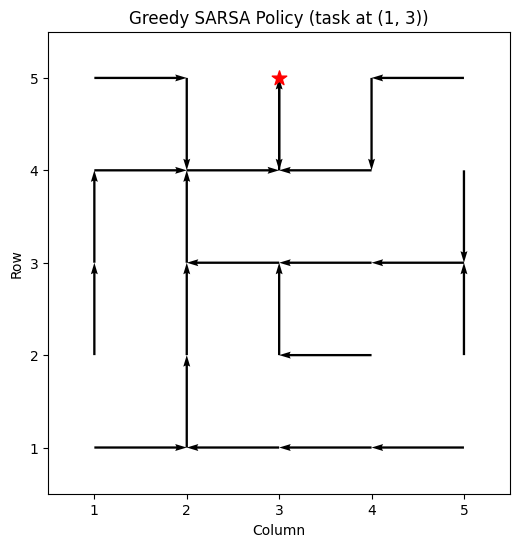

In [11]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/sarsa/train/c6f70031/policy.pkl'         # path to your pickled Q dict
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)                  # Q: dict[state] -> np.array of action‑values

# --- 2) VISUALIZATION PARAMETERS -------------
task = (1, 3)                            # fixed task location
n_rows, n_cols = 5, 5                  # dimensions of your grid
action_map = {
    0: (-1,  0),   # up
    1: ( 0,  1),   # right
    2: ( 1,  0),   # down
    3: ( 0, -1),   # left
    # extend for any extra actions you have
}

# --- 3) BUILD VECTOR FIELD + COLOR CODES ----
X, Y, U, V, colors = [], [], [], [], []
for i in range(1,n_rows+1):
    for j in range(1,n_cols+1):
        state = ((i, j), task)
        if state in Q:
            qvals = Q[state]
            col = 'black'           # seen in training
        else:
            qvals = np.zeros(len(action_map))
            col = 'red'             # never visited during training

        best_action = int(np.argmax(qvals))
        dx, dy = action_map[best_action]

        # quiver uses (x, y) = (col, row), flipping row so (0,0) is bottom‑left
        X.append(j)
        Y.append(n_rows - i+1)   # flip row so (0,0) is at bottom‑left
        U.append(dy)
        V.append(-dx)
        colors.append(col)

# --- 4) PLOT WITH QUIVER -----------------------
plt.figure(figsize=(6,6))
plt.quiver(
    X, Y, U, V,
    angles='xy', scale_units='xy', scale=1,
    width=0.005, color=colors
)

# mark the task
tx, ty = task
plt.scatter([ty], [n_rows + 1 - tx], color='red', s=120, marker='*', label='Task')

# add legend for visited vs. unseen
visited_patch = mpatches.Patch(color='black', label='Visited in training')
unseen_patch  = mpatches.Patch(color='red',   label='Unseen state')
# plt.legend(handles=[visited_patch, unseen_patch], loc='upper right')

plt.xlim(0.5, n_cols + 0.5)
plt.ylim(0.5, n_rows + 0.5)
plt.gca().set_aspect('equal')
plt.title(f"Greedy SARSA Policy (task at {task})")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()


In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/dc7dde26/policy.pkl'
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)  

In [2]:
Q

{(0,
  (0,
   0,
   0,
   0)): array([43.17174744, 11.66218507, 13.87518469, 12.47939052, 33.50948537]),
 (3,
  (0,
   0,
   0,
   0)): array([ 8.7424757 , 15.53471408, 11.04168073, 43.81166008, 35.14242441]),
 (1,
  (0,
   0,
   0,
   0)): array([ 7.68264283, 43.20282353, 12.11852941, 13.17038117, 29.03698188]),
 (2,
  (0,
   0,
   0,
   0)): array([15.86462279, 12.51771245, 43.95987774, 11.38042294, 33.93101094]),
 (4,
  (0,
   0,
   0,
   0)): array([24.87723429,  0.        ,  3.29708375,  2.28900483,  4.5       ])}

In [ ]:
state = ((1, 0, 2, 1),
  1,
  (1,
   3,
   3,
   1,
   2))
Q

{((1, 0, 2, 1),
  1,
  (1,
   3,
   3,
   1,
   2)): array([144.4232333 ,  74.71507351,  76.00220413,  72.72682029]),
 ((0, 2, 2, 1),
  2,
  (0,
   2,
   2,
   5,
   1)): array([109.43924619, 164.103034  , 111.36810171, 102.32052992]),
 ((0, 2, 2, 2),
  8,
  (1,
   1,
   1,
   5,
   0)): array([134.56479166,  42.32036628,  -0.28431195,  20.18387656]),
 ((0, 2, 2, 2),
  3,
  (5,
   5,
   5,
   5,
   5)): array([  2.77157318,  13.50857029, 106.82139772,  24.07340994]),
 ((0, 1, 0, 2),
  4,
  (4,
   4,
   5,
   5,
   5)): array([  5.49524568, 123.89515612,   7.62689688,  17.08354251]),
 ((0, 0, 2, 2),
  4,
  (5,
   3,
   5,
   5,
   4)): array([ 47.84082087,  42.90961525, 147.85820756,  44.81172558]),
 ((1, 0, 2, 1),
  4,
  (5,
   2,
   4,
   4,
   3)): array([ 36.83786691,   8.95433862, 146.28531244,  37.73997226]),
 ((2, 0, 2, 0),
  4,
  (5,
   1,
   3,
   3,
   2)): array([ 70.70451737,  55.94615565, 170.61502453,  47.64043009]),
 ((2, 0, 1, 2),
  4,
  (5,
   0,
   2,
   2,
   1)): arr

## Checking a log

In [7]:
import re

def extract_array(observation_line, key):
    # Example pattern: "'task_positions': array([4, 4, 4, 2, 2, 1]"
    pattern = rf"'{key}'\s*:\s*array\(\[([^\]]+)\]"
    match = re.search(pattern, observation_line)
    if match:
        nums_str = match.group(1)
        # Convert each number as an integer, ignoring extra spaces
        return [int(num.strip()) for num in nums_str.split(',')]
    return []

completed_tasks = 0
prev_task_positions = None

# Replace 'path/to/your/log_file.txt' with your actual log file path.
with open("tmp.txt", "r") as f:
    for line in f:
        # Process only observation lines 
        if line.startswith("Observation:"):
            task_positions = extract_array(line, "task_positions")
            ugv_positions = extract_array(line, "ugv_positions")
            print("ugv_positions", ugv_positions)
            print("task_positions", task_positions)
            
            if prev_task_positions is not None:
                for pos in ugv_positions:
                    if pos in prev_task_positions:
                        completed_tasks += 1
                        print("Task completed at position:", pos)
            # Update previous task_positions for next observation check
            prev_task_positions = task_positions

print("Total tasks completed:", completed_tasks)

ugv_positions [3, 2]
task_positions [5, 3, 5, 5, 5, 4]
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task

## Checking Occupancy Grid

In [7]:
import networkx as nx
import pandas as pd
def _build_graph(df_maze):
        G = nx.Graph()
        for _, row in df_maze.iterrows():
            r, c = int(row['row']), int(row['col'])
            G.add_node((r, c))
            if row['E'] == 1:
                G.add_edge((r, c), (r, c+1), traffic=0)
            if row['W'] == 1:
                G.add_edge((r, c), (r, c - 1), traffic=0)
            if row['N'] == 1:
                G.add_edge((r, c), (r - 1, c), traffic=0)
            if row['S'] == 1:
                G.add_edge((r, c), (r + 1,c), traffic=0)

        # directions = [(-1, 0), (0, 1), (1, 0), (0, -1)]
        # for node in G.nodes:
        #     wall_distances = []
        #     for dr, dc in directions:
        #         steps = 0
        #         current = node
        #         while steps < 1:
        #             next_node = (current[0] + dr, current[1] + dc)
        #             if not G.has_edge(current, next_node):
        #                 break
        #             steps += 1
        #             current = next_node
        #         wall_distances.append(steps)
        #     G.nodes[node]['wall_distance'] = wall_distances

        # Wall Occupancy Grid 
        max_row = df_maze['row'].max()
        max_col = df_maze['col'].max()
        kernel_size = 3
        for i in range(1,max_row+1):
            for j in range(i,max_col+1):
                occupancy_grid = [0]*kernel_size*(kernel_size+1)*2
                m = len(occupancy_grid)
                for k in range(m):
                    if k<m//2:
                        row_id = k//kernel_size
                        col_id = k%kernel_size
                        row_t_diff = row_id-2
                        row_b_diff = row_id-1
                        col_diff = col_id-1
                        cell_t = (i+row_t_diff,j+col_diff)
                        cell_b = (i+row_b_diff,j+col_diff)
                        if G.has_edge(cell_t,cell_b):
                            occupancy_grid[k] = 1
                    else:
                        k_ = k-m//2
                        row_id = k_%kernel_size
                        col_id = k_//kernel_size
                        col_l_diff = col_id-2
                        col_r_diff = col_id-1
                        row_diff = row_id-1
                        cell_l = (j+row_diff,i+col_l_diff)
                        cell_r = (j+row_diff,i+col_r_diff)
                        if G.has_edge(cell_l,cell_r):
                            occupancy_grid[k] = 1
                G.nodes[(i,j)]['occupancy_grid'] = occupancy_grid

        return G

In [8]:
df_maze = pd.read_csv("data/rl_maze.csv")
G = _build_graph(df_maze)

In [9]:
G.nodes[(2,2)]['occupancy_grid']

[0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1]

In [6]:
i,j = 2,2
kernel_size = 3
occupancy_grid = [0]*kernel_size*(kernel_size+1)*2
m = len(occupancy_grid)
for k in range(m):
    if k<m//2:
        row_id = k//kernel_size
        col_id = k%kernel_size
        row_t_diff = row_id-2
        row_b_diff = row_id-1
        col_diff = col_id-1
        cell_t = (i+row_t_diff,j+col_diff)
        cell_b = (i+row_b_diff,j+col_diff)
        if G.has_edge(cell_t,cell_b):
            occupancy_grid[k] = 1
    else:
        k_ = k-m//2
        print(k_)
        row_id = k_%kernel_size
        col_id = k_//kernel_size
        print(row_id,col_id)
        col_l_diff = col_id-2
        col_r_diff = col_id-1
        row_diff = row_id-1
        cell_l = (j+row_diff,i+col_l_diff)
        cell_r = (j+row_diff,i+col_r_diff)
        print(cell_l,cell_r)
        if G.has_edge(cell_l,cell_r):
            occupancy_grid[k] = 1
G.nodes[(i,j)]['occupancy_grid'] = occupancy_grid

0
0 0
(1, 0) (1, 1)
1
1 0
(2, 0) (2, 1)
2
2 0
(3, 0) (3, 1)
3
0 1
(1, 1) (1, 2)
4
1 1
(2, 1) (2, 2)
5
2 1
(3, 1) (3, 2)
6
0 2
(1, 2) (1, 3)
7
1 2
(2, 2) (2, 3)
8
2 2
(3, 2) (3, 3)
9
0 3
(1, 3) (1, 4)
10
1 3
(2, 3) (2, 4)
11
2 3
(3, 3) (3, 4)


# Checking if a State is in a Polcy

In [1]:
import pickle
import ast

# Prompt the user for the pickle file path and state tuple
policy_path = "runs/sarsa/c00d345d/policy.pkl"
state = ((3, 1, 3, 1, 5), (0, 0, 0, 0))

# Convert the input string to a tuple safely
try:
    # state = ast.literal_eval(state_input)
    if not isinstance(state, tuple):
        raise ValueError("Input is not a tuple.")
except Exception as e:
    print("Invalid state tuple input:", e)
    raise

# Load the policy from the provided pickle file
try:
    with open(policy_path, 'rb') as f:
        policy = pickle.load(f)
except Exception as e:
    print(f"Error loading policy from {policy_path}: {e}")
    raise

# Check if the state is in the policy dictionary
if state in policy:
    print(f"State {state} is present in the policy pickle file.")
    print(f"Action values: {policy[state]}")
else:
    print(f"State {state} is NOT present in the policy pickle file.")

State ((3, 1, 3, 1, 5), (0, 0, 0, 0)) is present in the policy pickle file.
Action values: [1174.07049016  324.39017714   83.22633506  453.48865802  272.12460621]


# Checking Atari Env

In [3]:
import gymnasium as gym
env = gym.make("PongNoFrameskip-v4", render_mode="rgb_array")
env = gym.wrappers.RecordEpisodeStatistics(env)

# observation, info = env.reset(seed=42)
# done = False
# while True:
#     action = env.action_space.sample()
#     observation, reward, terminated, truncated, info = env.step(action)
#     if terminated or truncated:
#         observation, info = env.reset()
# env.close()

In [5]:
env.observation_space.shape

(210, 160, 3)

# Checking RecordStat Wrapper

In [1]:
import gymnasium as gym
import yaml

import envs

In [11]:
config = yaml.safe_load(open("runs/dijkstra/config.yaml"))
env = gym.make("LMDEnv-v0", config=config, render_mode="print")
env = gym.wrappers.RecordEpisodeStatistics(env)

In [12]:
obs, info = env.reset(seed=42)

/home/shinobi-owl/anaconda3/envs/clean_rl/lib/python3.10/site-packages/gymnasium/utils/passive_env_checker.py:188: UserWarning: WARN: The obs returned by the `reset()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


In [31]:
info

{'time_elapsed': 350.0,
 'current_timestep': 7,
 'num_tasks_completed': 2,
 'total_ev_distance': 350.0,
 'total_energy_consumed': 350.0,
 'avg_task_completion_time': 300.0,
 'active_tasks': [(8, 6)],
 'red_roads': [((2, 5), (3, 5)),
  ((3, 5), (3, 6)),
  ((3, 5), (4, 5)),
  ((4, 5), (5, 5)),
  ((3, 6), (3, 7)),
  ((3, 6), (4, 6)),
  ((5, 6), (4, 6)),
  ((3, 7), (2, 7)),
  ((4, 6), (4, 7)),
  ((4, 7), (5, 7))],
 'yellow_roads': [((3, 4), (3, 5)),
  ((2, 5), (2, 6)),
  ((4, 4), (4, 5)),
  ((1, 6), (2, 6)),
  ((5, 5), (5, 6)),
  ((3, 7), (3, 8)),
  ((4, 7), (4, 8))],
 'episode': {'r': array([45.], dtype=float32),
  'l': array([6], dtype=int32),
  't': array([117.31592], dtype=float32)}}

In [28]:
obs

array([101, 101,   0,   2,   1,   0,   0,   0,   0], dtype=int32)

In [30]:
obs, reward, terminated, truncated, info = env.step(2)

In [10]:
env.close()

# SUMO

## SumoNetVis

In [1]:
import networkx as nx
import SumoNetVis
import matplotlib.pyplot as plt

In [2]:
def build_graph(map):
    G = nx.Graph()
    net = SumoNetVis.Net(map)

    juncs = net.junctions

    # Add nodes for each edge in the SUMO network
    for edge in net.edges.values():
        # Get the from and to junctions for this edge
        if edge.from_junction_id is None or edge.to_junction_id is None:
            continue
        from_junction = edge.from_junction_id
        to_junction = edge.to_junction_id

        G.add_node(from_junction, x=juncs[from_junction].x, y=juncs[from_junction].y)
        G.add_node(to_junction, x=juncs[to_junction].x, y=juncs[to_junction].y)

        # Add edge between the junctions
        G.add_edge(from_junction, to_junction, traffic=0)#, weight=edge.getLength())

    # Calculate all shortest path lengths for observation space
    all_shortest_path_lengths = dict(nx.all_pairs_shortest_path_length(G))

    return G, all_shortest_path_lengths

In [3]:
G = build_graph("data/slc/slc.net.xml")[0]

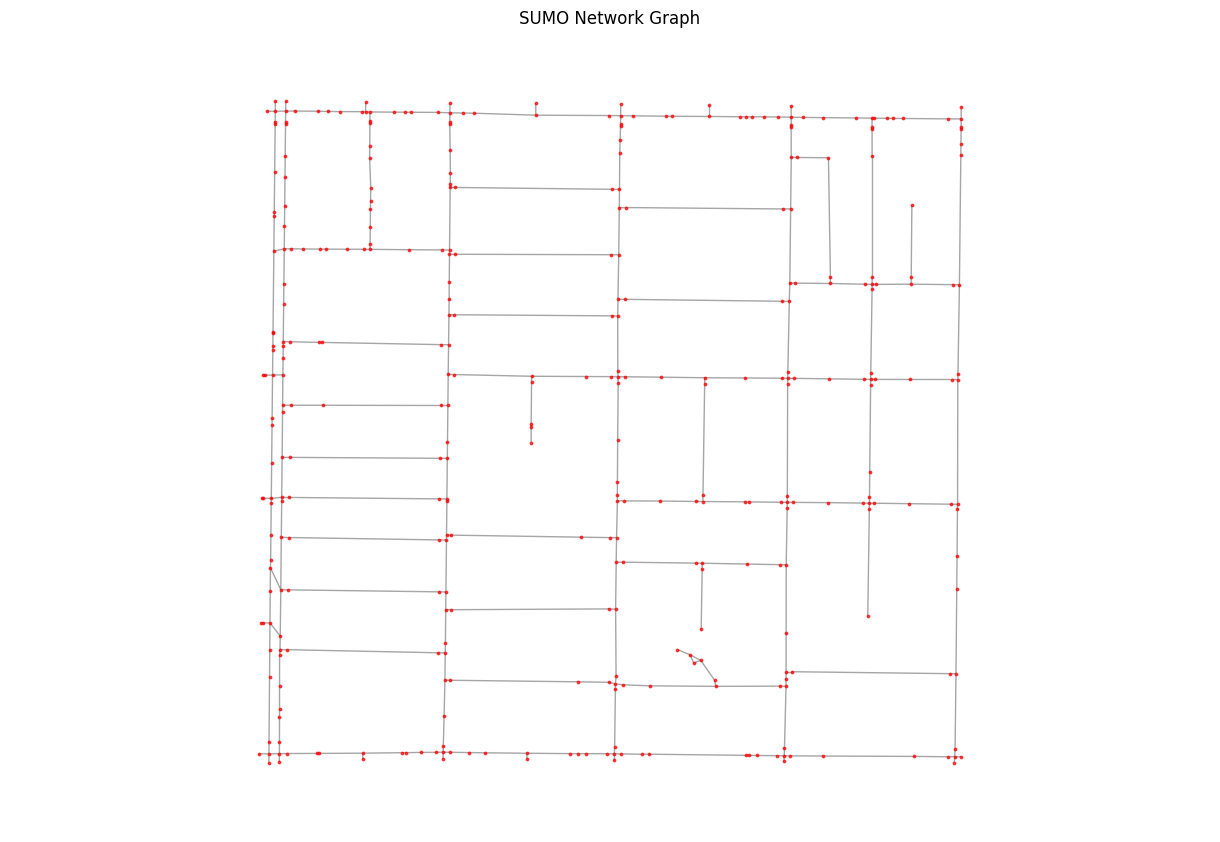

In [4]:
# Extract node positions from x,y attributes
pos = {node: (data['x'], data['y']) for node, data in G.nodes(data=True)}

# Create the plot
plt.figure(figsize=(12, 8))
nx.draw(G, pos, with_labels=False, node_color='red', node_size=3, 
    font_size=8, edge_color='gray', alpha=0.7)
plt.title("SUMO Network Graph")
plt.axis('equal')
plt.show()

## Sumo Grid Generating and Traffic

In [ ]:
#!/usr/bin/env python3
# TraCI-only edge monitor. Connects to an already running SUMO (started with --remote-port).
# Reports: per-step veh count, mean speed, occupancy; plus cumulative entrants and flow (veh/h).

import argparse
import time
from statistics import mean

import traci

def avg_edge_occupancy(edge_id: str) -> float:
    """Return average occupancy (0..1) across all lanes of edge."""
    lane_ids = traci.edge.getLaneIDs(edge_id)
    if not lane_ids:
        return 0.0
    vals = [traci.lane.getLastStepOccupancy(l) for l in lane_ids]  # fraction 0..1
    return sum(vals) / len(vals)

def main():
    ap = argparse.ArgumentParser(description="Monitor traffic on a SUMO edge via TraCI.")
    ap.add_argument("--host", default="127.0.0.1")
    ap.add_argument("--port", type=int, default=8813, help="SUMO --remote-port")
    ap.add_argument("--edge", required=True, help="Target edge ID (not an internal ':' edge)")
    ap.add_argument("--duration", type=int, default=1000, help="Seconds to monitor")
    ap.add_argument("--print-every", type=int, default=1, help="Print interval (steps)")
    args = ap.parse_args()

    print(f"Connecting to SUMO at {args.host}:{args.port} ...")
    conn = traci.connect(args.port, args.host)
    traci.switch(conn.getLabel())

    # Validate edge
    if args.edge not in traci.edge.getIDList():
        raise SystemExit(f"Edge '{args.edge}' not found in network.")

    # Collectors
    entrants = 0                        # vehicles that *entered* the edge (flow)
    prev_on_edge = set()                # vehicles present on edge in previous step
    speeds = []                         # mean speed time series
    counts = []                         # vehicle count time series
    occs = []                           # occupancy time series
    step = 0

    # Optional: read step length to scale results correctly
    # (you set it with --step-length when starting SUMO)
    # We’ll assume 1s if not available.
    try:
        step_length = traci.simulation.getDeltaT() / 1000.0  # ms -> s
    except Exception:
        step_length = 1.0

    print(f"Monitoring edge '{args.edge}' for {args.duration}s (step={step_length}s) ...")

    # Advance until we cover the desired window
    end_time = traci.simulation.getTime() + args.duration
    while traci.simulation.getTime() < end_time or traci.simulation.getMinExpectedNumber() > 0:
        traci.simulationStep()

        # Vehicles currently on edge
        now_on_edge = set(traci.edge.getLastStepVehicleIDs(args.edge))
        count = len(now_on_edge)
        counts.append(count)

        # Entrants = vehicles that were not on the edge last step
        step_entrants = len(now_on_edge - prev_on_edge)
        entrants += step_entrants
        prev_on_edge = now_on_edge

        # Mean speed (m/s) for vehicles observed on edge in the last step
        mean_speed = traci.edge.getLastStepMeanSpeed(args.edge) if count > 0 else 0.0
        speeds.append(mean_speed)

        # Occupancy (0..1), averaged across lanes
        occ = avg_edge_occupancy(args.edge)
        occs.append(occ)

        if (step % args.print_every) == 0:
            print(
                f"[t={int(traci.simulation.getTime()):4d}] "
                f"count={count:3d}  entrants+{step_entrants:2d}  "
                f"meanSpeed={mean_speed:6.2f} m/s  occ={occ:.3f}"
            )
        step += 1

        # If you started SUMO with a very small --step-length, this small sleep
        # makes the log readable; otherwise you can remove it.
        # time.sleep(0.0)

    # Window length in hours for flow computation
    window_s = args.duration
    window_h = max(window_s, 1e-6) / 3600.0
    flow_veh_per_h = entrants / window_h

    print("\n=== Summary ===")
    print(f"Edge:         {args.edge}")
    print(f"Duration:     {args.duration} s")
    print(f"Step length:  {step_length} s")
    print(f"Avg count:    {mean(counts):.2f} veh")
    print(f"Avg speed:    {mean(speeds):.2f} m/s")
    print(f"Avg occup.:   {mean(occs):.3f} (fraction)")
    print(f"Cumulative entrants: {entrants} veh")
    print(f"Flow:         {flow_veh_per_h:.1f} veh/h")

    traci.close()

if __name__ == "__main__":
    main()


TraCIException: Invalid type 'passenger' for vehicle 'veh0'.

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/aa63c747/policy.pkl'         # path to your pickled Q dict
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)                  # Q: dict[state] -> np.array of action‑values


In [2]:
Q

{(23, 24): array([48.11243699,  0.        ,  0.        ,  0.        ]),
 (18,
  24): array([-1.02009680e-08, -8.81835407e-13,  4.94975335e+01,  0.00000000e+00]),
 (13,
  24): array([-8.62822687e-06, -9.27440030e-08, -1.17983413e-04,  4.86387046e+01]),
 (8,
  24): array([-1.08404931e-04, -1.38411704e-08, -2.17340692e-06,  4.61596187e+01]),
 (7,
  24): array([-1.16803579e-05, -1.13245940e-07,  3.61132185e+01, -7.13729186e-12]),
 (2,
  24): array([-1.32313500e-02, -1.16712415e-04,  7.14137757e+00, -1.50000000e+00]),
 (1,
  24): array([-1.20285000e-01, -1.15545291e-05,  6.21848760e-01, -1.50000000e+00]),
 (0,
  24): array([-1.02950854e-06, -1.29692918e-04, -4.06500000e+00, -2.85000013e+00]),
 (3,
  24): array([-1.17891329e-03, -1.66669797e-03,  1.35910838e+01, -2.85000000e+00]),
 (6,
  24): array([-1.19093589e-02, -2.51395650e-02,  1.75433480e+01, -9.79817119e-13]),
 (4, 24): array([-0.13365   ,  0.88191272, -2.85011671, -1.5       ]),
 (9, 24): array([-0.14458915, 10.91847408, -0.13365   

# Build Graph from Sumo Traci with sidewalks

In [1]:
import numpy as np
import networkx as nx
import traci

In [2]:
def build_graph():
    G = nx.DiGraph()

    # Get all edges (skip internal)
    edge_ids = [e for e in traci.edge.getIDList() if not e.startswith(":")]

    for eid in edge_ids:
        from_node = traci.edge.getFromJunction(eid)
        to_node = traci.edge.getToJunction(eid)

        lid = f"{eid}_0"  # Assume single lane per edge for simplicity
        length = traci.lane.getLength(lid)
        speed = traci.edge.getLastStepMeanSpeed(eid)

        # Add nodes (junctions)
        fx, fy = traci.junction.getPosition(from_node)
        tx, ty = traci.junction.getPosition(to_node)
        G.add_node(from_node, x=fx, y=fy)
        G.add_node(to_node, x=tx, y=ty)

        # Add directed edge with attributes
        G.add_edge(
            from_node,
            to_node,
            id=eid,
            length=length,
            speed=speed,
            weight=length / speed if speed > 0 else float("inf")
        )

    all_shortest_path_lengths = dict(nx.all_pairs_shortest_path_length(G))
    return G, all_shortest_path_lengths


In [3]:
Sumo_config = [
    'sumo',
    '-c', "data/grid/grid.sumocfg",
    '--step-length', '1',
    '--start'
]
traci.start(Sumo_config)

# Maze State
# G, all_shortest_path_lengths = build_graph() # Rebuild graph with new maze

 Retrying in 1 seconds


(22, 'SUMO 1.24.0')

In [4]:
all_edges = traci.edge.getIDList()

In [6]:
traci.close()

Step #0.00 (0ms ?*RT. ?UPS, TraCI: 133818ms, vehicles TOT 0 ACT 0 BUF 0)                 


# Checking S, SA visits

In [5]:
from itertools import islice
import pickle

fontsize_title = 20
fontsize_label = 20
fontsize_ticks = 16

# Load pickle and ensure we get a Python dict
path = "runs/c75c5609/training_results.pkl"

with open(path, "rb") as f:
    training_results = pickle.load(f)

print("Loaded type:", type(training_results))

# If it's not already a dict, try to convert
if not isinstance(training_results, dict):
    try:
        training_results = dict(training_results)
        print("Converted loaded object to dict.")
    except Exception as e:
        print("Could not convert to dict:", e)

# Summary of contents
if isinstance(training_results, dict):
    print(f"Dictionary with {len(training_results)} keys. Showing up to 10 keys and value types:")
    for k, v in islice(training_results.items(), 10):
        print(" -", k, ":", type(v))
else:
    print("training_results is not a dict. Inspect the object directly:", training_results)

Loaded type: <class 'dict'>
Dictionary with 4 keys. Showing up to 10 keys and value types:
 - state_visits : <class 'dict'>
 - sa_visits : <class 'dict'>
 - new_states_explored : <class 'list'>
 - new_sa_explored : <class 'list'>


In [6]:
state_visits = training_results.get('state_visits', {})
sa_visits = training_results.get('sa_visits', {})
new_states_explored = training_results.get('new_states_explored', [])
new_sa_explored = training_results.get('new_sa_explored', [])

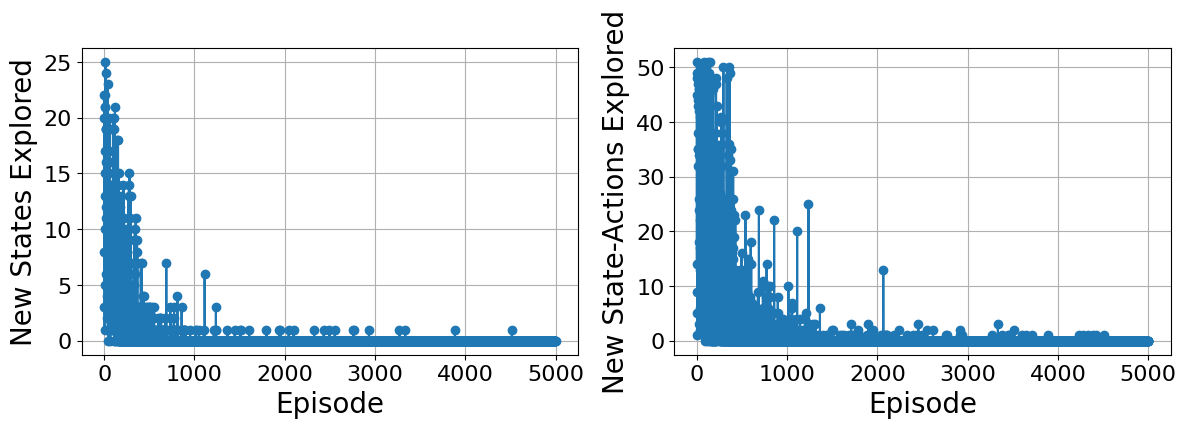

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(len(new_states_explored)), new_states_explored, marker='o', linestyle='-')
# axes[0].set_title('New States Explored vs Episode', fontsize=fontsize_title)
axes[0].set_xlabel('Episode', fontsize=fontsize_label)
axes[0].set_ylabel('New States Explored', fontsize=fontsize_label)
axes[0].tick_params(axis='both', which='major', labelsize=fontsize_ticks)
axes[0].grid(True)

axes[1].plot(range(len(new_sa_explored)), new_sa_explored, marker='o', linestyle='-')
# axes[1].set_title('New State-Actions Explored vs Episode', fontsize=fontsize_title)
axes[1].set_xlabel('Episode', fontsize=fontsize_label)
axes[1].set_ylabel('New State-Actions Explored', fontsize=fontsize_label)
axes[1].tick_params(axis='both', which='major', labelsize=fontsize_ticks)
axes[1].grid(True)

plt.tight_layout()
plt.show()


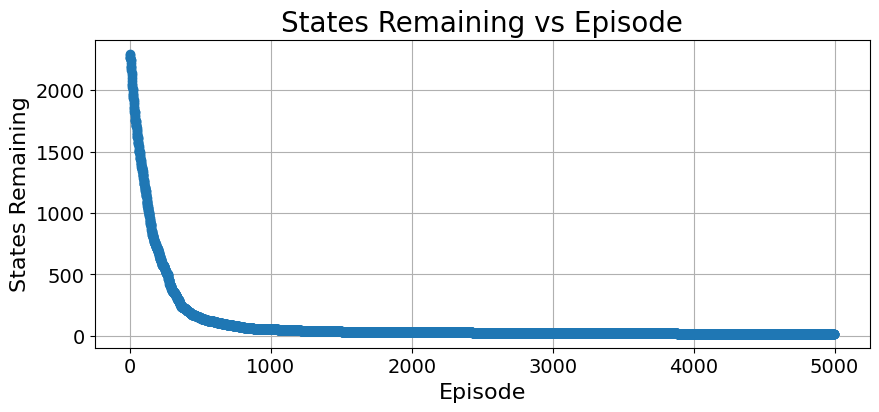

In [17]:
import numpy as np
new_states_explored_sum = np.cumsum(new_states_explored)
states_remaining = 2320-new_states_explored_sum
import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.plot(range(len(states_remaining)), states_remaining, marker='o', linestyle='-')
plt.title('States Remaining vs Episode', fontsize=fontsize_title)
plt.xlabel('Episode', fontsize=fontsize_label)
plt.ylabel('States Remaining', fontsize=fontsize_label)
plt.tick_params(axis='both', which='major', labelsize=fontsize_ticks)
plt.grid(True)
plt.show()

In [18]:
len(state_visits)

2317

In [25]:
len(sa_visits)

8321

# Visualizing a Route in SUMO

In [ ]:
import numpy as np
import networkx as nx
import traci
import sumolib
import random

In [ ]:
Sumo_config = [
    'sumo-gui',
    '-c', "data/rand_grid/rand_grid.sumocfg",
    '--step-length', '1',
    '--delay', '400',
    '--start'
]
traci.start(Sumo_config)

# Maze State
# G, all_shortest_path_lengths = build_graph() # Rebuild graph with new maze

 Retrying in 1 seconds


Fontconfig warning: "/usr/share/fontconfig/conf.avail/05-reset-dirs-sample.conf", line 6: unknown element "reset-dirs"


(22, 'SUMO 1.24.0')

In [ ]:
veh_id = f"ugv"
route_edges = ['-11', ':10_c1', ':10_c0', '-109']
traci.person.add(veh_id, route_edges[0], -1)
traci.person.setColor(veh_id, (255, 0, 0, 255))
traci.person.appendWalkingStage(veh_id, route_edges, 
                                arrivalPos=-1, speed=3.0)
traci.simulationStep()

In [ ]:
while veh_id in traci.person.getIDList():
    traci.simulationStep()

In [ ]:
traci.close()

# Finding Average Edge Travel Time

In [1]:
import numpy as np
import networkx as nx
import traci
import sumolib
import random

In [2]:

net = sumolib.net.readNet("data/rand_grid/rand_grid.net.xml")

Sumo_config = [
    'sumo',
    '-c', "data/rand_grid/rand_grid.sumocfg",
    '--step-length', '1',
    '--start'
]
traci.start(Sumo_config)
edges = net.getEdges()

 Retrying in 1 seconds


In [3]:
time_elapsed = 0
current_timestep = 0
travel_times = []
while time_elapsed < 15000:
    veh_id = f"ugv_{time_elapsed}"
    randomedge = random.choice(edges)._id
    traci.person.add(veh_id, randomedge, 0)
    traci.person.appendWalkingStage(veh_id, [randomedge], 
                                    arrivalPos=-1, speed=5.0)
    traci.simulationStep()
    time_elapsed = traci.simulation.getTime()
    start_time = time_elapsed
    while veh_id in traci.person.getIDList():
        traci.simulationStep()
        time_elapsed = traci.simulation.getTime()
    travel_times.append(time_elapsed - start_time)

Step #13400.00 (0ms ?*RT. ?UPS, TraCI: 0ms, vehicles TOT 2681 ACT 13 BUF 0)               tep #4500.00 (0ms ?*RT. ?UPS, TraCI: 0ms, vehicles TOT 901 ACT 15 BUF 0)                 ep #9000.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 1801 ACT 15 BUF 0)                

In [4]:
traci.close()

Step #15013.00 (0ms ?*RT. ?UPS, TraCI: 4585ms, vehicles TOT 3003 ACT 13 BUF 0)            


In [5]:
travel_times = np.array(travel_times)
print(f"Average travel time: {np.mean(travel_times)} s")

Average travel time: 28.094961240310077 s


In [ ]:
import numpy as np
import time
import networkx as nx
import random
import pandas as pd
from tqdm import tqdm
from datetime import timedelta
from collections import defaultdict
import pickle
import yaml

import traci
import sumolib

In [ ]:
Sumo_config = [
    'sumo',
    '-c', "data/tmp/tmp.sumocfg",
    '--step-length', '1',
    '--scale', '1',
    '--start'
]
traci.start(Sumo_config)

time_elapsed = 0
while time_elapsed < 15000:
    traci.simulationStep()
    time_elapsed = traci.simulation.getTime()

 Retrying in 1 seconds
Step #13400.00 (1ms ~= 1000.00*RT, ~0.00UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)      Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)                       tep #4500.00 (1ms ~= 1000.00*RT, ~0.00UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)       tep #4500.00 (1ms ~= 1000.00*RT, ~0.00UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)       ep #9000.00 (2ms ~= 500.00*RT, ~0.00UPS, TraCI: 0ms, vehicles TOT 0 ACT 0 BUF 0)        ep #9000.00 (2ms ~= 500.00*RT, ~0.00UPS, TraCI: 0ms, vehicles TOT 0 ACT 0 BUF 0)        

In [ ]:
def get_centroid(shape):
    """Calculates the center point of a shape (list of x,y tuples)."""
    if not shape:
        return 0, 0
    x_coords = [p[0] for p in shape]
    y_coords = [p[1] for p in shape]
    return np.mean(x_coords), np.mean(y_coords)

def build_graph(net_path,):
    net_path = net_path.replace('.sumocfg', '.net.xml')
    net = sumolib.net.readNet(net_path, withPedestrianConnections=True)
    junctions = net.getNodes()
    edge_eps = {}
    junc2nodes_map = defaultdict(list)
    
    for junction in junctions:
        connections = junction.getConnections()
        for connection in connections:
            # 1. Inspect the source of the connection
            ep = None
            edge = None
            dir = None
            if connection._from.getFunction() == 'walkingarea':
                ep = connection._from
                edge = connection._to
                dir = 0
            elif connection._to.getFunction() == 'walkingarea':
                ep = connection._to
                edge = connection._from
                dir = 1
            if ep and edge:
                edge_id = edge.getID()
                eps = [None, None]
                eps[dir] = ep
                if edge_id not in edge_eps:
                    edge_eps[edge_id] = {
                        "edge": edge,
                        "eps": eps
                    }
                else:
                    edge_eps[edge_id]["eps"][dir] = ep
                    if len([ep for ep in edge_eps[edge_id]["eps"] if ep is not None]) > 2:
                        print("More than 2 entry points for edge ", edge_id)
                        raise ValueError("More than 2 entry points for edge ", edge_id)

    G = nx.DiGraph()
    for edge_id, edge_data in edge_eps.items():
        entry_points = edge_data["eps"]
        for ep in entry_points:
            shape = ep.getShape()
            cx, cy = get_centroid(shape)
            G.add_node(ep._id, junc_id=ep._from._id,junc_coord=ep._from._coord, x=cx, y=cy)
            junc2nodes_map[ep._from._id].append(ep._id)
        edge_obj = edge_data["edge"]
        edge_length = None
        edge_type = edge_obj.getFunction()
        edge_est_tt = None
        edge_mean_speed = None
        for lane_obj in edge_obj.getLanes():
            if "pedestrian" in lane_obj._allowed:
                edge_est_tt = traci.lane.getTraveltime(lane_obj.getID())
                edge_mean_speed = traci.lane.getLastStepMeanSpeed(lane_obj.getID())
        if edge_type == 'crossing':
            edge_length = 5.0
            G.add_edge(entry_points[0]._id, entry_points[1]._id, id=edge_obj._id, length=edge_length, type=edge_type,
                        est_tt=edge_est_tt, mean_speed = edge_mean_speed)
            # G.add_edge(entry_points[1]._id, entry_points[0]._id, edge=edge_obj._id, length=edge_length, type=edge_type)
        else:
            edge_length = edge_obj.getLength()
            edge_type = 'sidewalk'
            G.add_edge(entry_points[0]._id, entry_points[1]._id, id=edge_obj._id, length=edge_length, type=edge_type, 
                       est_tt=edge_est_tt, mean_speed=edge_mean_speed)
    
    G_und = G.to_undirected()



    all_shortest_path_lengths = dict(nx.all_pairs_dijkstra_path_length(G_und, weight='length'))
    return G_und, G, all_shortest_path_lengths, junc2nodes_map

net_path = "data/tmp/tmp.net.xml"
G, G_dir, all_shortest_path_lengths, junc2nodes_map = build_graph(net_path,)
junction_list = list(junc2nodes_map.keys())
node2idx = {node: idx for idx, node in enumerate(sorted(G.nodes))}
idx2node = {idx: node for node, idx in node2idx.items()}
traci.close()

Step #15000.00 (2ms ~= 500.00*RT, ~0.00UPS, TraCI: 85ms, vehicles TOT 0 ACT 0 BUF 0)      


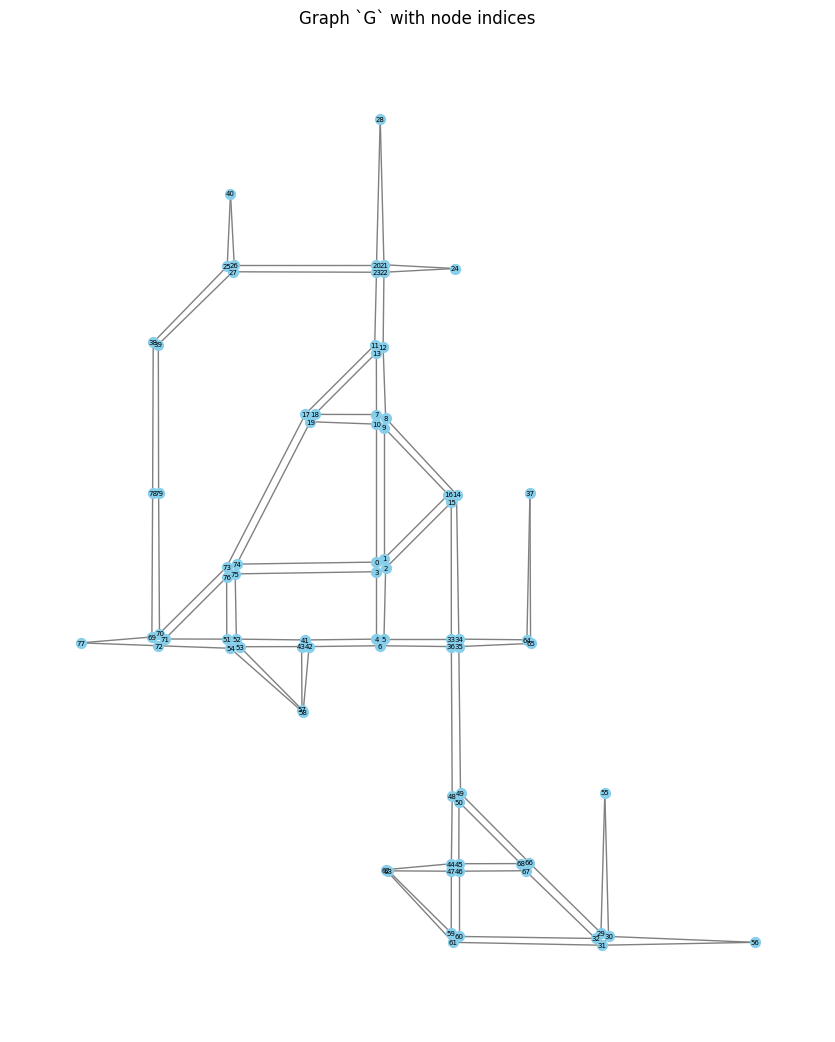

In [ ]:
# Plot Graph G and label nodes with their indices
import matplotlib.pyplot as plt

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G.nodes(data=True)}

# Labels: map node -> index from node2idx
labels = {n: node2idx[n] for n in G.nodes()}

plt.figure(figsize=(10, 10))
# Draw nodes and edges
nx.draw(G, pos=pos, with_labels=False, node_size=50, node_color='skyblue', edge_color='gray')
# Draw labels (node indices)
nx.draw_networkx_labels(G, pos, labels=labels, font_size=5)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Graph `G` with node indices')
plt.axis('off')
plt.show()


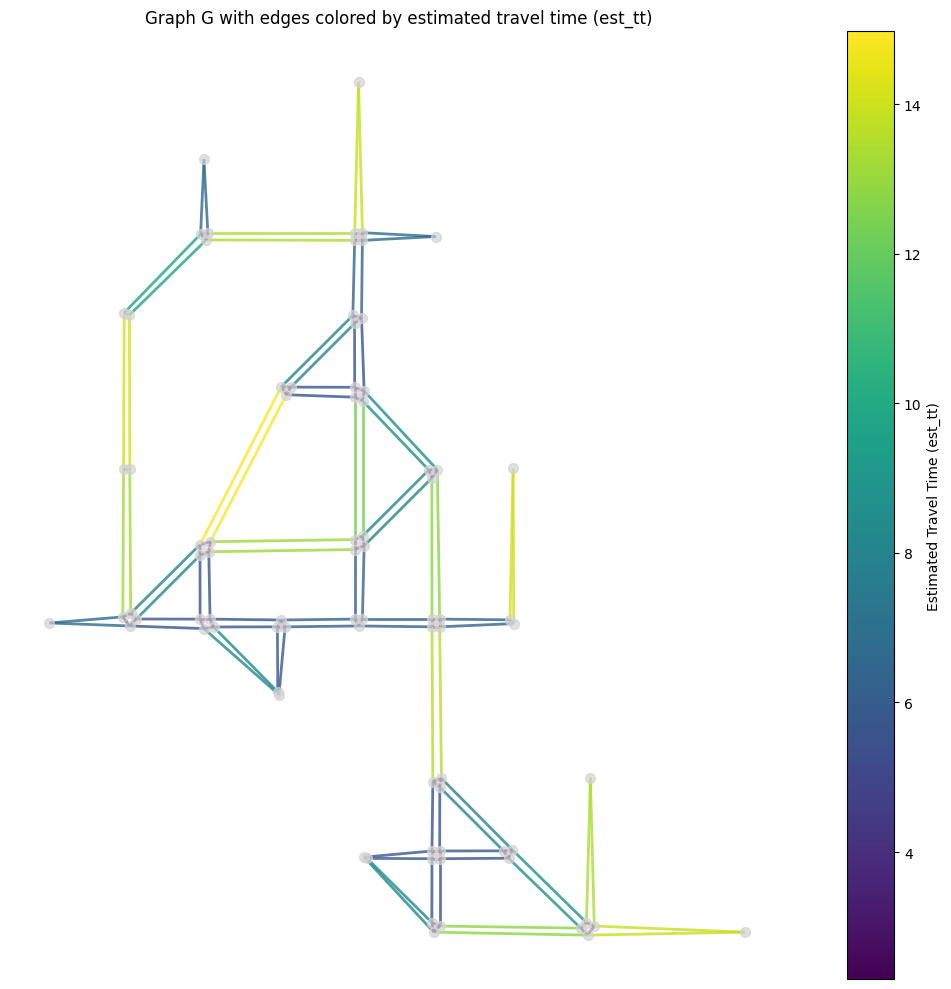

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G.nodes(data=True)}

# Extract est_tt values for edges
edge_est_tt = []
edges_with_tt = []
for u, v, data in G.edges(data=True):
    if 'est_tt' in data and data['est_tt'] is not None:
        edge_est_tt.append(data['est_tt'])
        edges_with_tt.append((u, v))

# Create colormap
if edge_est_tt:
    vmin = min(edge_est_tt)
    vmax = max(edge_est_tt)
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.cm.viridis
    
    plt.figure(figsize=(12, 10))
    
    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_size=50, node_color='lightgray', alpha=0.7)
    
    # Draw edges with color based on est_tt
    for (u, v), tt in zip(edges_with_tt, edge_est_tt):
        nx.draw_networkx_edges(G, pos, [(u, v)], 
                              edge_color=[cmap(norm(tt))], 
                              width=2, alpha=0.8)
    
    # Add colorbar
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=plt.gca(), label='Estimated Travel Time (est_tt)')
    
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title('Graph G with edges colored by estimated travel time (est_tt)')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No edges with est_tt values found.")

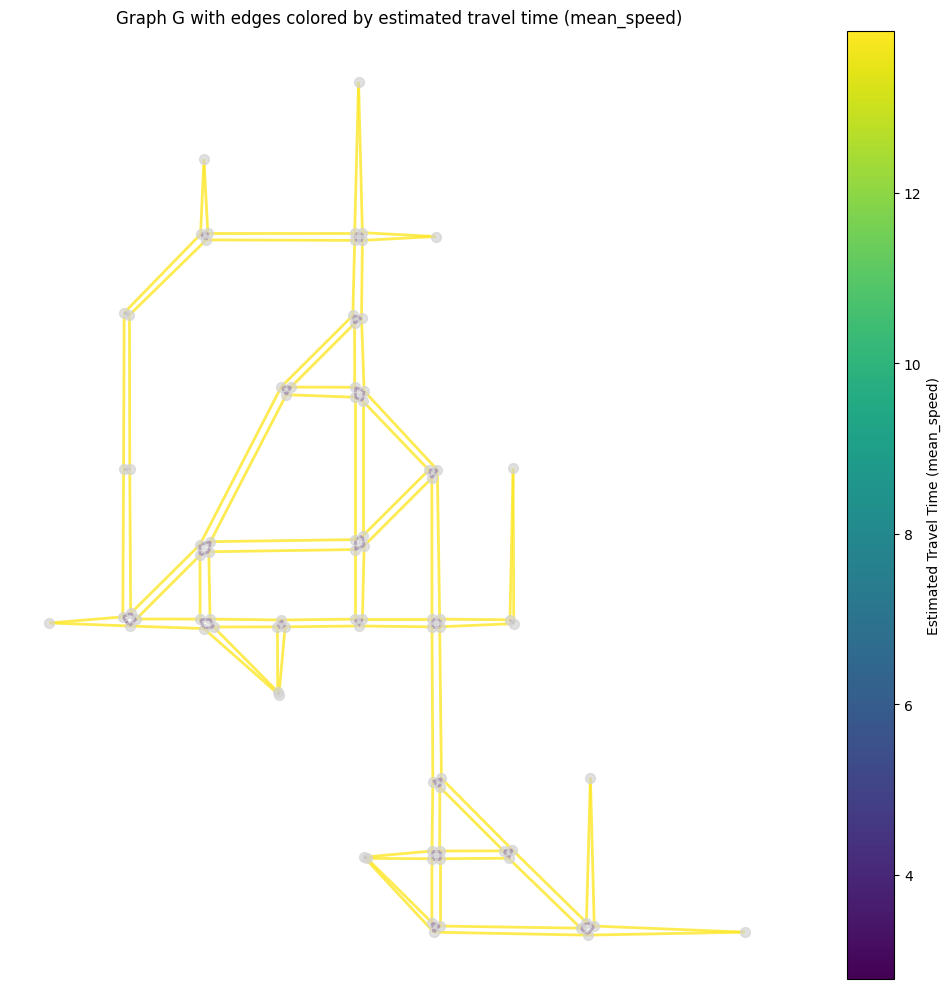

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G.nodes(data=True)}

# Extract mean_speed values for edges
edge_mean_speed = []
edges_with_tt = []
for u, v, data in G.edges(data=True):
    if 'mean_speed' in data and data['mean_speed'] is not None:
        edge_mean_speed.append(data['mean_speed'])
        edges_with_tt.append((u, v))

# Create colormap
if edge_mean_speed:
    vmin = min(edge_mean_speed)
    vmax = max(edge_mean_speed)
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.cm.viridis
    
    plt.figure(figsize=(12, 10))
    
    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_size=50, node_color='lightgray', alpha=0.7)
    
    # Draw edges with color based on mean_speed
    for (u, v), tt in zip(edges_with_tt, edge_mean_speed):
        nx.draw_networkx_edges(G, pos, [(u, v)], 
                              edge_color=[cmap(norm(tt))], 
                              width=2, alpha=0.8)
    
    # Add colorbar
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=plt.gca(), label='Estimated Travel Time (mean_speed)')
    
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title('Graph G with edges colored by estimated travel time (mean_speed)')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No edges with mean_speed values found.")

# Building Graph With Crosswalks

In [ ]:
import networkx as nx
import sumolib
import matplotlib.pyplot as plt
import numpy as np # Added for easier mean calculation

def get_centroid(shape):
    """Calculates the center point of a shape (list of x,y tuples)."""
    if not shape:
        return 0, 0
    x_coords = [p[0] for p in shape]
    y_coords = [p[1] for p in shape]
    return np.mean(x_coords), np.mean(y_coords)

In [ ]:
# def build_graph(net):
#     junctions = net.getNodes()
#     edge_eps = {}
#     wa_nodes = {}
    
#     for junction in junctions:
#         connections = junction.getConnections()
#         for connection in connections:
#             # 1. Inspect the source of the connection
#             if connection._from.getFunction() == 'walkingarea':
#                 # Store the actual walking area object (Edge/Lane), NOT the parent junction
#                 wa_nodes[connection._from.getID()] = connection._from
                
#                 edge_id = connection._to.getID()
#                 if edge_id not in edge_eps:
#                     edge_eps[edge_id] = [connection._from.getID()]
#                 else:
#                     edge_eps[edge_id].append(connection._from.getID())
            
#             # 2. Inspect the destination of the connection
#             elif connection._to.getFunction() == 'walkingarea':
#                 # Store the actual walking area object
#                 wa_nodes[connection._to.getID()] = connection._to
                
#                 edge_id = connection._from.getID()
#                 if edge_id not in edge_eps:
#                     edge_eps[edge_id] = [connection._to.getID()]
#                 else:
#                     edge_eps[edge_id].append(connection._to.getID())

#     # Filter out edges that don't have exactly 2 entry points (to avoid the error)
#     # or handle the logic as per your requirements. 
#     # Here I keep your strict check but usually, you might want to skip malformed edges.
#     valid_edge_eps = {}
#     for eid, eps in edge_eps.items():
#         if len(eps) > 2:
#             print(f"Warning: Edge {eid} has > 2 entry points. Skipping edge in graph.")
#         elif len(eps) == 2:
#             valid_edge_eps[eid] = eps

#     G = nx.Graph()
#     for edge_id, entry_points in valid_edge_eps.items():
#         G.add_edge(entry_points[0], entry_points[1], edge=edge_id)

#     # 3. Assign coordinates based on the Walking Area shape
#     for wa_node_id, wa_obj in wa_nodes.items():
#         # wa_obj is the SUMO Edge/Lane object, which has a shape
#         shape = wa_obj.getShape() 
        
#         # Calculate the center of that specific walking area polygon
#         cx, cy = get_centroid(shape)
        
#         # Fallback: if shape is missing, try using the parent junction coord
#         if cx == 0 and cy == 0 and hasattr(wa_obj, '_from'):
#              # fallback to old logic if shape is empty
#              cx, cy = wa_obj._from.getCoord()

#         G.nodes[wa_node_id]['x'] = cx
#         G.nodes[wa_node_id]['y'] = cy

#     return G

def build_graph(net,):
        junctions = net.getNodes()
        edge_eps = {}
        
        for junction in junctions:
            connections = junction.getConnections()
            for connection in connections:
                # 1. Inspect the source of the connection
                ep = None
                edge = None
                dir = None
                if connection._from.getFunction() == 'walkingarea':
                    ep = connection._from
                    edge = connection._to
                    dir = 0
                elif connection._to.getFunction() == 'walkingarea':
                    ep = connection._to
                    edge = connection._from
                    dir = 1
                if ep and edge:
                    edge_id = edge.getID()
                    eps = [None, None]
                    eps[dir] = ep
                    if edge_id not in edge_eps:
                        edge_eps[edge_id] = {
                            "edge": edge,
                            "eps": eps
                        }
                    else:
                        edge_eps[edge_id]["eps"][dir] = ep
                        if len([ep for ep in edge_eps[edge_id]["eps"] if ep is not None]) > 2:
                            print("More than 2 entry points for edge ", edge_id)
                            raise ValueError("More than 2 entry points for edge ", edge_id)

        G = nx.DiGraph()
        for edge_id, edge_data in edge_eps.items():
            entry_points = edge_data["eps"]
            for ep in entry_points:
                shape = ep.getShape()
                cx, cy = get_centroid(shape)
                G.add_node(ep._id, junc_id=ep._from._id,junc_coord=ep._from._coord, x=cx, y=cy)
            edge_obj = edge_data["edge"]
            edge_length = None
            edge_type = edge_obj.getFunction()
            if edge_type == 'crossing':
                edge_length = 5.0
                G.add_edge(entry_points[0]._id, entry_points[1]._id, edge=edge_obj._id, length=edge_length, type=edge_type)
                # G.add_edge(entry_points[1]._id, entry_points[0]._id, edge=edge_obj._id, length=edge_length, type=edge_type)
            else:
                edge_length = edge_obj.getLength()
                edge_type = 'sidewalk'
                G.add_edge(entry_points[0]._id, entry_points[1]._id, edge=edge_obj._id, length=edge_length, type=edge_type)
        
        G_und = G.to_undirected()

        all_shortest_path_lengths = dict(nx.all_pairs_dijkstra_path_length(G_und, weight='length'))
        return G_und, G, all_shortest_path_lengths


/tmp/ipykernel_5352/909870509.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


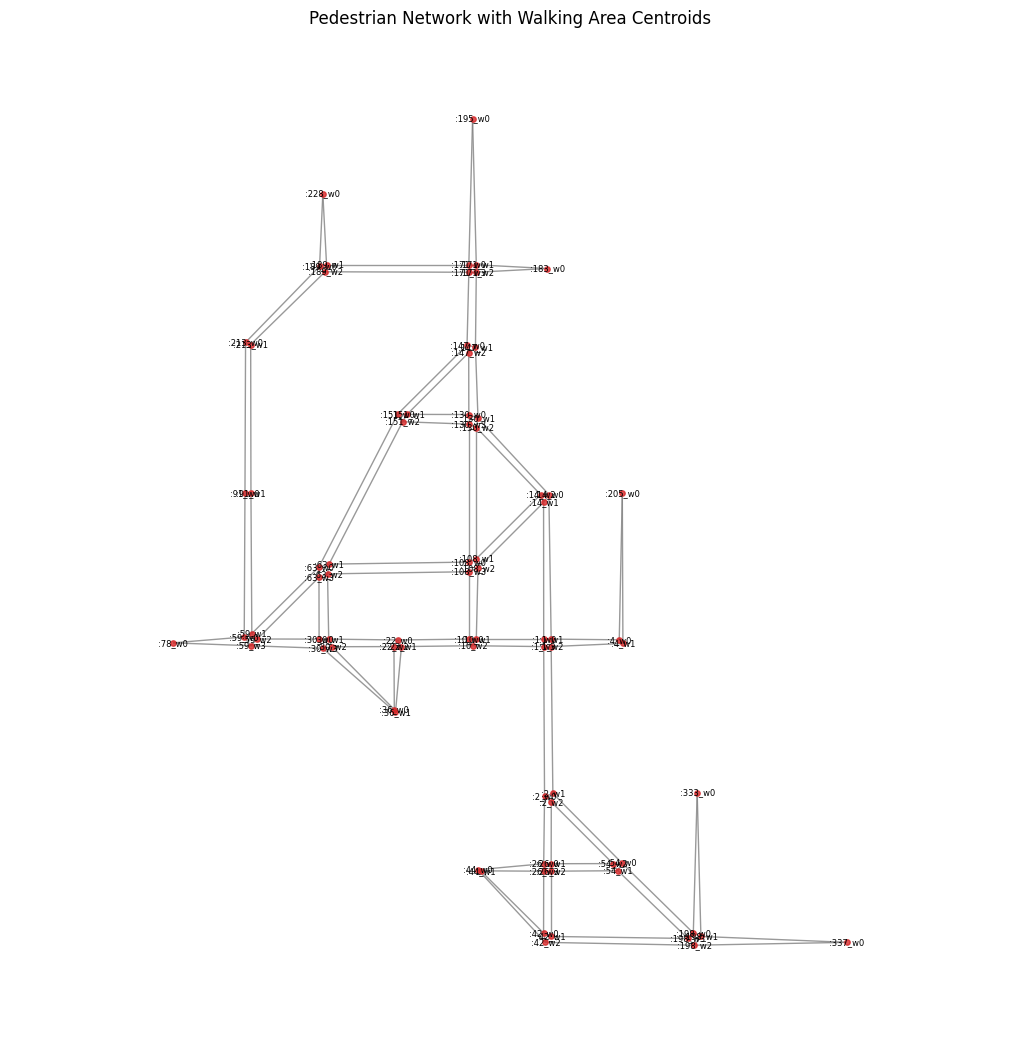

In [ ]:

net = sumolib.net.readNet("data/rand_grid/rand_grid.net.xml", withPedestrianConnections=True)
G,G_dir,_ = build_graph(net)

# Get positions
pos = {n: (d['x'], d['y']) for n, d in G.nodes(data=True)}

plt.figure(figsize=(10, 10))

# Draw nodes smaller so they don't overlap visually even if coordinates are close
nx.draw(G, pos, node_size=15, node_color='tab:red', edge_color='gray', with_labels=False, alpha=0.8)

# Labels
# Only draw labels if the graph isn't too dense
if len(G.nodes) < 100:
    nx.draw_networkx_labels(G, pos, font_size=6)

plt.title("Pedestrian Network with Walking Area Centroids")
plt.axis('equal') # Crucial for keeping the map aspect ratio correct
plt.tight_layout()
plt.show()

In [ ]:
G.edges[(':2_w0', ':2_w1')]

{'edge': ':2_c0', 'length': 5.0, 'type': 'crossing'}

In [ ]:
G.nodes[':2_w0']

{'junc_id': '2',
 'junc_coord': (500.0, 200.0, 0.0),
 'x': 496.1333333333334,
 'y': 194.79999999999998}

In [ ]:
# compute maximum degree and which nodes have it
degrees = dict(G.degree())
max_degree = max(degrees.values()) if degrees else 0
max_nodes = [n for n, d in degrees.items() if d == max_degree]

print("Max degree:", max_degree)
print("Nodes with max degree:", max_nodes)

Max degree: 4
Nodes with max degree: [':1_w1', ':1_w0', ':1_w2', ':1_w3', ':10_w1', ':14_w0', ':2_w0', ':10_w2', ':14_w1', ':2_w1', ':10_w0', ':22_w0', ':108_w2', ':108_w3', ':22_w1', ':108_w1', ':108_w0', ':63_w1', ':130_w2', ':14_w2', ':130_w3', ':63_w2', ':130_w1', ':130_w0', ':151_w1', ':147_w1', ':147_w2', ':151_w2', ':147_w0', ':151_w0', ':171_w2', ':171_w3', ':63_w0', ':171_w1', ':171_w0', ':189_w1', ':189_w2', ':189_w0', ':198_w1', ':198_w0', ':198_w2', ':198_w3', ':54_w0', ':42_w1', ':42_w2', ':54_w1', ':2_w2', ':26_w0', ':54_w2', ':26_w1', ':22_w2', ':30_w1', ':30_w2', ':26_w2', ':26_w3', ':42_w0', ':30_w0', ':30_w3', ':59_w2', ':59_w3', ':63_w3', ':59_w1', ':59_w0']


In [ ]:
# get unique junction ids from node attributes (skip nodes without 'junc_id')
junction_list = set(d.get('junc_id') for _, d in G.nodes(data=True))

# Visualizing a SUMO Policy 

In [1]:
import numpy as np
import time
import networkx as nx
import random
import pandas as pd
from tqdm import tqdm
from datetime import timedelta
from collections import defaultdict
import pickle
import yaml

import traci
import sumolib

In [2]:
policy_name = "c75c5609"
config_path = f"runs/{policy_name}/config.yaml"
policy_path = f"runs/{policy_name}/policy.pkl"
with open(policy_path, 'rb') as f:
    Q = pickle.load(f)
config = yaml.safe_load(open(config_path, 'r'))

In [3]:
def get_centroid(shape):
    """Calculates the center point of a shape (list of x,y tuples)."""
    if not shape:
        return 0, 0
    x_coords = [p[0] for p in shape]
    y_coords = [p[1] for p in shape]
    return np.mean(x_coords), np.mean(y_coords)

def build_graph(net_path,):
    net_path = net_path.replace('.sumocfg', '.net.xml')
    net = sumolib.net.readNet(net_path, withPedestrianConnections=True)
    junctions = net.getNodes()
    edge_eps = {}
    junc2nodes_map = defaultdict(list)
    
    for junction in junctions:
        connections = junction.getConnections()
        for connection in connections:
            # 1. Inspect the source of the connection
            ep = None
            edge = None
            dir = None
            if connection._from.getFunction() == 'walkingarea':
                ep = connection._from
                edge = connection._to
                dir = 0
            elif connection._to.getFunction() == 'walkingarea':
                ep = connection._to
                edge = connection._from
                dir = 1
            if ep and edge:
                edge_id = edge.getID()
                eps = [None, None]
                eps[dir] = ep
                if edge_id not in edge_eps:
                    edge_eps[edge_id] = {
                        "edge": edge,
                        "eps": eps
                    }
                else:
                    edge_eps[edge_id]["eps"][dir] = ep
                    if len([ep for ep in edge_eps[edge_id]["eps"] if ep is not None]) > 2:
                        print("More than 2 entry points for edge ", edge_id)
                        raise ValueError("More than 2 entry points for edge ", edge_id)

    G = nx.DiGraph()
    for edge_id, edge_data in edge_eps.items():
        entry_points = edge_data["eps"]
        for ep in entry_points:
            shape = ep.getShape()
            cx, cy = get_centroid(shape)
            G.add_node(ep._id, junc_id=ep._from._id,junc_coord=ep._from._coord, x=cx, y=cy)
            junc2nodes_map[ep._from._id].append(ep._id)
        edge_obj = edge_data["edge"]
        edge_length = None
        edge_type = edge_obj.getFunction()
        if edge_type == 'crossing':
            edge_length = 5.0
            G.add_edge(entry_points[0]._id, entry_points[1]._id, id=edge_obj._id, length=edge_length, type=edge_type)
            # G.add_edge(entry_points[1]._id, entry_points[0]._id, edge=edge_obj._id, length=edge_length, type=edge_type)
        else:
            edge_length = edge_obj.getLength()
            edge_type = 'sidewalk'
            G.add_edge(entry_points[0]._id, entry_points[1]._id, id=edge_obj._id, length=edge_length, type=edge_type)
    
    G_und = G.to_undirected()



    all_shortest_path_lengths = dict(nx.all_pairs_dijkstra_path_length(G_und, weight='length'))
    return G_und, G, all_shortest_path_lengths, junc2nodes_map

net_path = config['net']['net_path']
G, G_dir, all_shortest_path_lengths, junc2nodes_map = build_graph(net_path,)
junction_list = list(junc2nodes_map.keys())
node2idx = {node: idx for idx, node in enumerate(sorted(G.nodes))}
idx2node = {idx: node for node, idx in node2idx.items()}

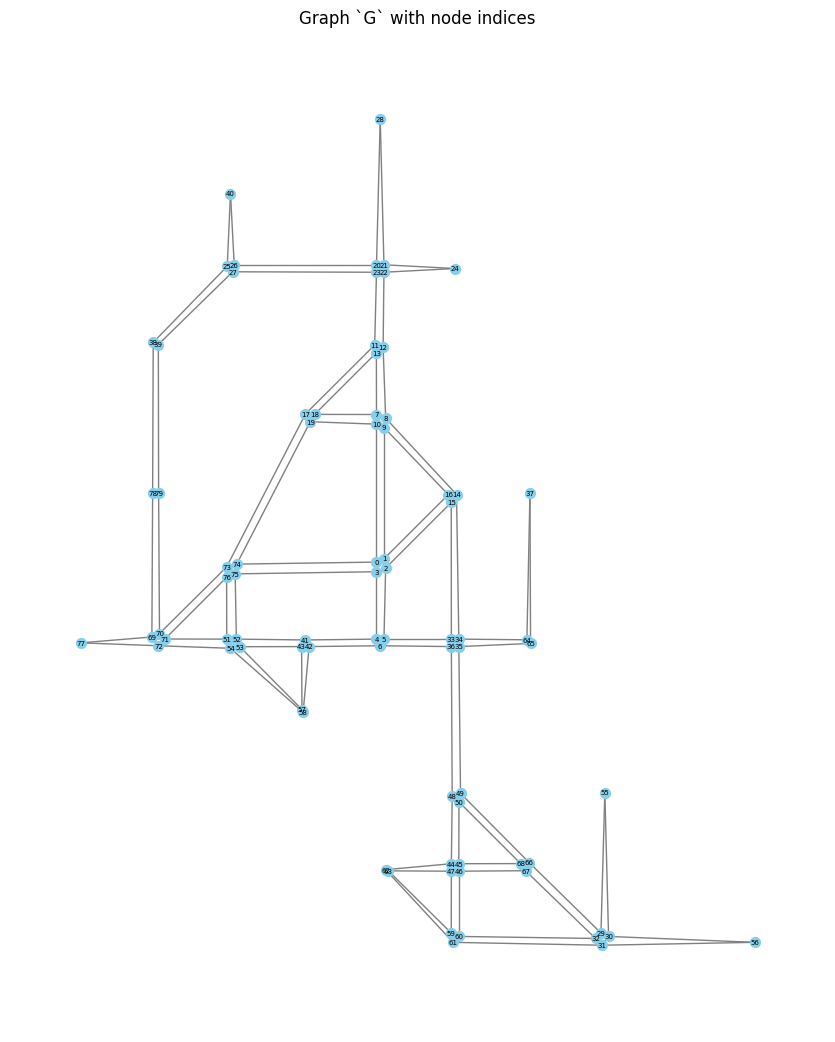

In [4]:
# Plot Graph G and label nodes with their indices
import matplotlib.pyplot as plt

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G.nodes(data=True)}

# Labels: map node -> index from node2idx
labels = {n: node2idx[n] for n in G.nodes()}

plt.figure(figsize=(10, 10))
# Draw nodes and edges
nx.draw(G, pos=pos, with_labels=False, node_size=50, node_color='skyblue', edge_color='gray')
# Draw labels (node indices)
nx.draw_networkx_labels(G, pos, labels=labels, font_size=5)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Graph `G` with node indices')
plt.axis('off')
plt.show()


In [5]:
import os

os.makedirs("tmp", exist_ok=True)
fig = plt.gcf()
fig.savefig("tmp/graph_G.png", dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [6]:
G_policy = nx.DiGraph()
target_junction = '1'
dij_Q = {}

for ori_node in G.nodes():
    ori_node_idx = node2idx[ori_node]
    target_nodes = junc2nodes_map[target_junction]
    target_node = target_nodes[np.argmin([all_shortest_path_lengths[ori_node][tn] for tn in target_nodes])]
    nb_nodes = list(G.neighbors(ori_node))  # Get up to num_actions neighbors
    nb_node_idxs = sorted([node2idx[nb] for nb in nb_nodes])[:4]
    steps2dest = []
    for nb_node_idx in nb_node_idxs:
        steps2dest.append(all_shortest_path_lengths[idx2node[nb_node_idx]][target_node])
    dij_Q[ori_node_idx] = np.array(steps2dest)

for ori_node in G.nodes():
    ori_node_idx = node2idx[ori_node]
    node_color, node_shape = None, None
    if G.nodes[ori_node]['junc_id'] == target_junction:
        node_color = 'green'
        node_shape = 'x'
    elif ori_node_idx in dij_Q:
        node_color = 'skyblue'
        node_shape = 'o'
    else:
        node_color = 'gray'
        node_shape = 'o'
    G_policy.add_node(ori_node, junc_id=G.nodes[ori_node]['junc_id'], x=G.nodes[ori_node]['x'], y=G.nodes[ori_node]['y'], color=node_color, shape=node_shape)

for pl_node_idx, q_values in dij_Q.items():
    pl_node = idx2node[pl_node_idx]
    nb_nodes = list(G.neighbors(pl_node))  # Get up to num_actions neighbors
    nb_node_idxs = sorted([node2idx[nb] for nb in nb_nodes])
    best_action = np.argmin(q_values)
    best_action_capped = np.argmin(q_values[:len(nb_node_idxs)])
    # print(len(nb_node_idxs), best_action)
    next_node_idx = nb_node_idxs[best_action_capped]
    next_node = idx2node[next_node_idx]
    G_policy.add_edge(pl_node, next_node)
    if best_action != best_action_capped:
        G_policy.nodes[pl_node]['color'] = 'red'  # Indicate discrepancy in action selection

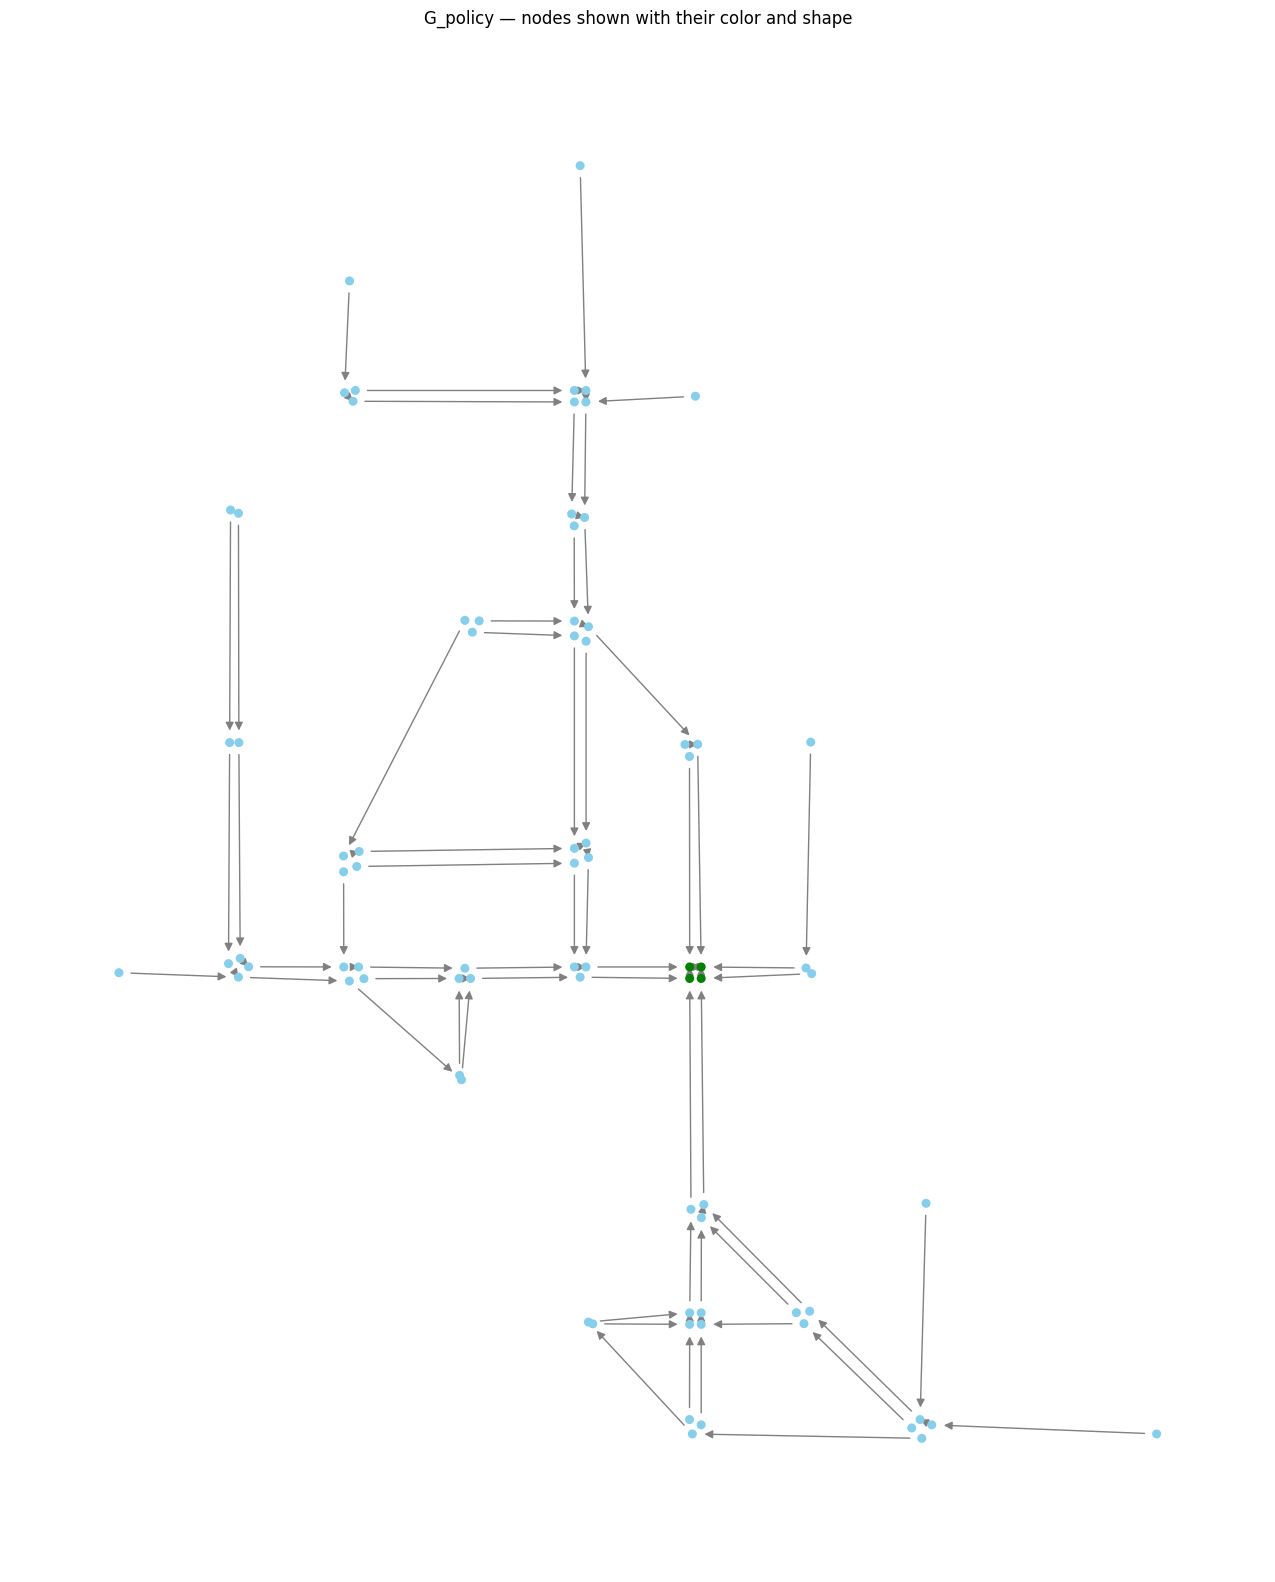

In [7]:
# Plot G_policy using node 'shape' and 'color' attributes
import matplotlib.pyplot as plt

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G_policy.nodes(data=True)}

plt.figure(figsize=(20, 20))
# Draw edges with arrows
nx.draw_networkx_edges(G_policy, pos, edge_color='gray', arrows=True, arrowstyle='-|>', arrowsize=12)

# Draw nodes grouped by their marker shape so matplotlib can apply correct marker per group
node_colors = [G_policy.nodes[n]['color'] for n in G_policy.nodes()]
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G_policy.nodes(data=True)}
nx.draw_networkx_nodes(G_policy, pos, node_color=node_colors, node_size=30)

plt.title('G_policy — nodes shown with their color and shape')
plt.axis('off')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

In [8]:
G_policy = nx.DiGraph()
target_junction = '1'
filtered_Q = {k[0]: v for k, v in Q.items() if k[1] == int(target_junction)}

for ori_node in G.nodes():
    ori_node_idx = node2idx[ori_node]
    node_color, node_shape = None, None
    if G.nodes[ori_node]['junc_id'] == target_junction:
        node_color = 'green'
        node_shape = 'x'
    elif ori_node_idx in filtered_Q:
        node_color = 'skyblue'
        node_shape = 'o'
    else:
        node_color = 'gray'
        node_shape = 'o'
    G_policy.add_node(ori_node, junc_id=G.nodes[ori_node]['junc_id'], x=G.nodes[ori_node]['x'], y=G.nodes[ori_node]['y'], color=node_color, shape=node_shape)

for pl_node_idx, q_values in filtered_Q.items():
    pl_node = idx2node[pl_node_idx]
    nb_nodes = list(G.neighbors(pl_node))  # Get up to num_actions neighbors
    nb_node_idxs = sorted([node2idx[nb] for nb in nb_nodes])
    best_action = np.argmax(q_values)
    best_action_capped = np.argmax(q_values[:len(nb_node_idxs)])
    # print(len(nb_node_idxs), best_action)
    next_node_idx = nb_node_idxs[best_action_capped]
    next_node = idx2node[next_node_idx]
    G_policy.add_edge(pl_node, next_node)
    if best_action != best_action_capped:
        G_policy.nodes[pl_node]['color'] = 'red'  # Indicate discrepancy in action selection

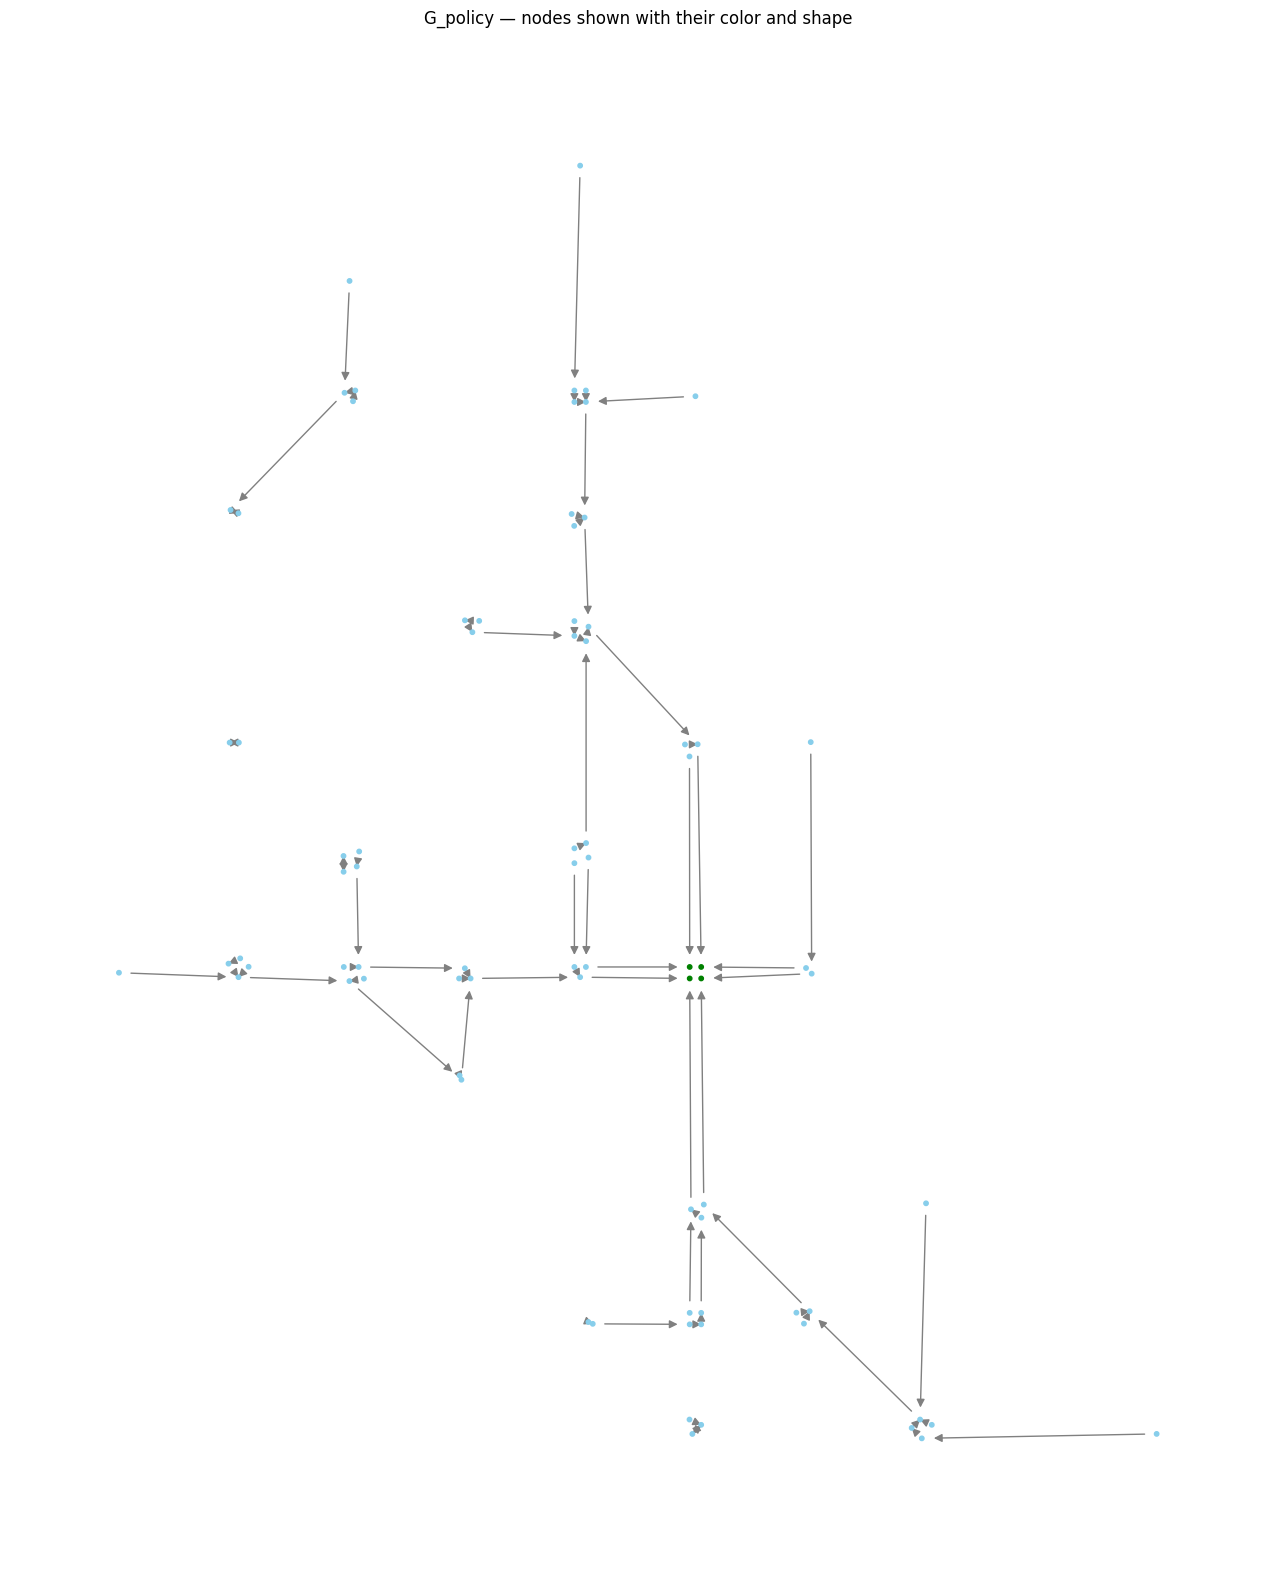

In [9]:
# Plot G_policy using node 'shape' and 'color' attributes
import matplotlib.pyplot as plt

# Build positions from node attributes (x, y)
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G_policy.nodes(data=True)}

plt.figure(figsize=(20, 20))
# Draw edges with arrows
nx.draw_networkx_edges(G_policy, pos, edge_color='gray', arrows=True, arrowstyle='-|>', arrowsize=12)

# Draw nodes grouped by their marker shape so matplotlib can apply correct marker per group
node_colors = [G_policy.nodes[n]['color'] for n in G_policy.nodes()]
pos = {n: (data.get('x', 0), data.get('y', 0)) for n, data in G_policy.nodes(data=True)}
nx.draw_networkx_nodes(G_policy, pos, node_color=node_colors, node_size=10)

plt.title('G_policy — nodes shown with their color and shape')
plt.axis('off')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()